In [ ]:
from google.colab import drive
from google.colab import files
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


In [ ]:
# train_dir =r'/content/drive/MyDrive/ms_data/train'
# test_dir=r'/content/drive/MyDrive/ms_data/test'


In [ ]:
train_dir=r'/content/drive/MyDrive/deepglobe_updated/train'
test_dir=r'/content/drive/MyDrive/deepglobe_updated/test'

In [ ]:

import tensorflow as tf
from tensorflow.keras import initializers
import os
import numpy as np
from tqdm import tqdm
from skimage.io import imread, imshow
from skimage.transform import resize
import matplotlib.pyplot as plt
import random
seed=14
np.random.seed=seed
img_width=512
img_height=512
img_channels=3

In [ ]:
train_img_dir = os.path.join(train_dir,'images/')
train_mask_dir = os.path.join(train_dir,'masks/')
test_img_dir = os.path.join(test_dir,'images/')
test_mask_dir = os.path.join(test_dir,'masks/')

In [ ]:
print(train_img_dir)
test_img_count = len(os.listdir(test_img_dir))
train_img_count=len(os.listdir(train_img_dir))
train_img_ids = os.listdir(train_img_dir)
test_img_ids = os.listdir(test_img_dir)
train_mask_count=len(os.listdir(train_mask_dir))
train_mask_ids=os.listdir(train_mask_dir)
print('Train image count is',train_img_count,'and their ids are',train_img_ids)
print('Mask image count is',train_mask_count,'and theur ids are',train_mask_ids)

/content/drive/MyDrive/deepglobe_updated/train/images/
Train image count is 6000 and their ids are ['img-5001.png', 'img-5002.png', 'img-5003.png', 'img-5004.png', 'img-5005.png', 'img-5006.png', 'img-5007.png', 'img-5008.png', 'img-5009.png', 'img-5010.png', 'img-5011.png', 'img-5012.png', 'img-5013.png', 'img-5014.png', 'img-5015.png', 'img-5016.png', 'img-5017.png', 'img-5018.png', 'img-5019.png', 'img-5020.png', 'img-5021.png', 'img-5022.png', 'img-5023.png', 'img-5024.png', 'img-5025.png', 'img-5026.png', 'img-5027.png', 'img-5028.png', 'img-5029.png', 'img-5030.png', 'img-5031.png', 'img-5032.png', 'img-5033.png', 'img-5034.png', 'img-5035.png', 'img-5036.png', 'img-5037.png', 'img-5038.png', 'img-5039.png', 'img-5040.png', 'img-5041.png', 'img-5042.png', 'img-5043.png', 'img-5044.png', 'img-5045.png', 'img-5046.png', 'img-5047.png', 'img-5048.png', 'img-5049.png', 'img-5050.png', 'img-5051.png', 'img-5052.png', 'img-5053.png', 'img-5054.png', 'img-5055.png', 'img-5056.png', 'img

In [ ]:
test_img_count=len(os.listdir(test_img_dir))
test_img_ids=os.listdir(test_img_dir)

In [ ]:
test_img_count = len(os.listdir(test_img_dir))
test_img_ids = os.listdir(test_img_dir)
print('Test image count is',test_img_count,'and their ids are',test_img_ids)

Test image count is 226 and their ids are ['img-6001.png', 'img-6002.png', 'img-6003.png', 'img-6004.png', 'img-6005.png', 'img-6006.png', 'img-6007.png', 'img-6008.png', 'img-6009.png', 'img-6010.png', 'img-6011.png', 'img-6012.png', 'img-6013.png', 'img-6014.png', 'img-6015.png', 'img-6016.png', 'img-6017.png', 'img-6018.png', 'img-6019.png', 'img-6020.png', 'img-6021.png', 'img-6022.png', 'img-6023.png', 'img-6024.png', 'img-6025.png', 'img-6026.png', 'img-6027.png', 'img-6028.png', 'img-6029.png', 'img-6030.png', 'img-6031.png', 'img-6032.png', 'img-6033.png', 'img-6034.png', 'img-6035.png', 'img-6036.png', 'img-6037.png', 'img-6038.png', 'img-6039.png', 'img-6040.png', 'img-6041.png', 'img-6042.png', 'img-6043.png', 'img-6044.png', 'img-6045.png', 'img-6046.png', 'img-6047.png', 'img-6048.png', 'img-6049.png', 'img-6050.png', 'img-6051.png', 'img-6052.png', 'img-6053.png', 'img-6054.png', 'img-6055.png', 'img-6056.png', 'img-6057.png', 'img-6058.png', 'img-6059.png', 'img-6060.png

In [ ]:
X_train = np.zeros((train_mask_count,img_width,img_height,img_channels),dtype=np.uint8)
y_train = np.zeros((len(train_mask_ids),img_width,img_height,1),dtype=np.bool_)

In [ ]:
print('Resizing train images and masks')
for n,img_name in tqdm(enumerate(train_mask_ids),total=len(train_mask_ids)):
    path = train_img_dir + img_name
    img = imread(path)[:,:,:img_channels]
    img = resize(img,(img_width,img_height),mode='constant',preserve_range=True)
    X_train[n] = img

    mask = np.zeros((img_width,img_height,1),dtype=np.bool_)
    msk = imread(train_mask_dir+img_name)
    # If the mask is RGB, convert it to a 2D boolean mask first
    if msk.ndim == 3:
        msk = np.any(msk[:, :, :3] > 0, axis=-1)

    msk = np.expand_dims(resize(msk.astype(np.float32),(img_width,img_height),mode='constant',preserve_range=True),axis=-1)
    msk = msk > 0.5
    mask = np.maximum(mask,msk)
    y_train[n] = mask

Resizing train images and masks


100%|██████████| 6000/6000 [2:00:46<00:00,  1.21s/it]


In [ ]:
X_test = np.zeros((test_img_count,img_width,img_height,img_channels),dtype=np.uint8)
y_test_ground_truth = np.zeros((len(test_img_ids),img_width,img_height,1),dtype=np.bool_)


In [ ]:
print('Resizing test images')
for i,img_name in tqdm(enumerate(test_img_ids),total=len(test_img_ids)):
    path = test_img_dir + img_name
    img = imread(path)[:,:,:img_channels]
    img = resize(img,(img_width,img_height),mode='constant',preserve_range=True)
    X_test[i] = img

Resizing test images


100%|██████████| 226/226 [02:43<00:00,  1.38it/s]


In [ ]:
print('Resizing test masks')
for n,img_name in tqdm(enumerate(test_img_ids),total=len(test_img_ids)):
    mask = np.zeros((img_width,img_height,1),dtype=np.bool_)
    msk = imread(test_mask_dir+img_name)
    # If the mask is RGB, convert it to a 2D boolean mask first
    if msk.ndim == 3:
        msk = np.any(msk[:, :, :3] > 0, axis=-1)
    msk = np.expand_dims(resize(msk.astype(np.float32),(img_width,img_height),mode='constant',preserve_range=True),axis=-1)
    msk = msk > 0.5
    mask = np.maximum(mask,msk)
    y_test_ground_truth[n] = mask

Resizing test masks


100%|██████████| 226/226 [02:13<00:00,  1.69it/s]


In [ ]:
input_shape = (img_height, img_width, img_channels)

In [ ]:
from tensorflow.keras import models, layers, regularizers
from tensorflow.keras import backend as K
from tensorflow.keras.optimizers import Adam
#from evaluation_metrics import IoU_coef,IoU_loss

In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model

In [ ]:
def aspp_block(x, num_filters, rate_scale=1):
    x1 = conv_block(num_filters, (3, 3), dilation_rate=(6 * rate_scale, 6 * rate_scale), padding="SAME")(x)
    x1 = layers.BatchNormalization()(x1)

    x2 = conv_block(num_filters, (3, 3), dilation_rate=(12 * rate_scale, 12 * rate_scale), padding="SAME")(x)
    x2 = layers.BatchNormalization()(x2)

    x3 = conv_block(num_filters, (3, 3), dilation_rate=(18 * rate_scale, 18 * rate_scale), padding="SAME")(x)
    x3 = layers.BatchNormalization()(x3)

    x4 = conv_block(num_filters, (3, 3), padding="SAME")(x)
    x4 = layers.BatchNormalization()(x4)

    y = Add()([x1, x2, x3, x4])
    y = conv_block(num_filters, (1, 1), padding="SAME")(y)
    return y


In [ ]:
def stem_block(x, n_filter, strides):
    x_init = x

    ## Conv 1
    x = Conv2D(n_filter, (3, 3), padding="same", strides=strides)(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Conv2D(n_filter, (3, 3), padding="same")(x)

    ## Shortcut
    s  = Conv2D(n_filter, (1, 1), padding="same", strides=strides)(x_init)
    s = BatchNormalization()(s)
    x = Add()([x, s])
    return x



In [ ]:
def resnet_block(x, n_filter, strides=1):
    x_init = x

    ## Conv 1
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Conv2D(n_filter, (3, 3), padding="same", strides=strides)(x)
    ## Conv 2
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Conv2D(n_filter, (3, 3), padding="same", strides=1)(x)

    ## Shortcut
    s  = Conv2D(n_filter, (1, 1), padding="same", strides=strides)(x_init)
    s = BatchNormalization()(s)

    ## Add
    x = Add()([x, s])
    return x

In [ ]:
def aspp_block(x, num_filters, rate_scale=1):
    x1 = Conv2D(num_filters, (3, 3), dilation_rate=(6 * rate_scale, 6 * rate_scale), padding="SAME")(x)
    x1 = BatchNormalization()(x1)

    x2 = Conv2D(num_filters, (3, 3), dilation_rate=(12 * rate_scale, 12 * rate_scale), padding="SAME")(x)
    x2 = BatchNormalization()(x2)

    x3 = Conv2D(num_filters, (3, 3), dilation_rate=(18 * rate_scale, 18 * rate_scale), padding="SAME")(x)
    x3 = BatchNormalization()(x3)

    x4 = Conv2D(num_filters, (3, 3), padding="SAME")(x)
    x4 = BatchNormalization()(x4)

    y = Add()([x1, x2, x3, x4])
    y = Conv2D(num_filters, (1, 1), padding="SAME")(y)
    return y

In [ ]:
def attetion_block(g, x):
    """
        g: Output of Parallel Encoder block
        x: Output of Previous Decoder block
    """

    filters = x.shape[-1]

    g_conv = BatchNormalization()(g)
    g_conv = Activation("relu")(g_conv)
    g_conv = Conv2D(filters, (3, 3), padding="SAME")(g_conv)

    g_pool = MaxPooling2D(pool_size=(2, 2), strides=(2, 2))(g_conv)

    x_conv = BatchNormalization()(x)
    x_conv = Activation("relu")(x_conv)
    x_conv = Conv2D(filters, (3, 3), padding="SAME")(x_conv)

    gc_sum = Add()([g_pool, x_conv])

    gc_conv = BatchNormalization()(gc_sum)
    gc_conv = Activation("relu")(gc_conv)
    gc_conv = Conv2D(filters, (3, 3), padding="SAME")(gc_conv)

    gc_mul = Multiply()([gc_conv, x])
    return gc_mul

In [ ]:
#Attention U-NET
def attentionunet(input_shape, dropout=0.2, batchnorm=True):

    n_filters = [16, 32, 64, 128, 256]
    kernelsize = 3
    upsample_size = 2

    inputs = layers.Input(input_shape)
    c0 = inputs
    c1 = stem_block(c0, n_filters[0], strides=1)

    ## Encoder
    c2 = resnet_block(c1, n_filters[1], strides=2)
    c3 = resnet_block(c2, n_filters[2], strides=2)
    c4 = resnet_block(c3, n_filters[3], strides=2)
    c5 = resnet_block(c4, n_filters[4], strides=2)

    ## Bridge
    b1 = aspp_block(c5, n_filters[4])
    #b2 = aspp_block(c4, n_filters[3])

    ## Decoder
    d0 = attetion_block(c4, b1)
    d0 = UpSampling2D((2, 2))(d0)
    d0 = Concatenate()([d0, c4])
    d0 = resnet_block(d0, n_filters[4])

    #d1 = attetion_block(c3, b2)
    d1 = attetion_block(c3, d0)
    d1 = UpSampling2D((2, 2))(d1)
    d1 = Concatenate()([d1, c3])
    d1 = resnet_block(d1, n_filters[3])


    d2 = attetion_block(c2, d1)
    d2 = UpSampling2D((2, 2))(d2)
    d2 = Concatenate()([d2, c2])
    d2 = resnet_block(d2, n_filters[2])

    d3 = attetion_block(c1, d2)
    d3 = UpSampling2D((2, 2))(d3)
    d3 = Concatenate()([d3, c1])
    d3 = resnet_block(d3, n_filters[1])

    ## output
    #outputs = aspp_block(d3, n_filters[0])
    outputs=d3
    outputs = Conv2D(1, (1, 1), padding="same")(outputs)
    outputs = Activation("sigmoid")(outputs)

    ## Model
    model = Model(inputs, outputs)
    model.summary()
    return model


In [ ]:
model = attentionunet(input_shape)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 512, 512,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 512, 512,  │        448 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 512, 512,  │         64 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 512, 512,  │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 512, 512,  │         64 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 512, 512,  │      2,320 │ activation[0][0]  │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512, 512,  │         64 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 512, 512,  │          0 │ conv2d_1[0][0],   │
│                     │ 16)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 16)        │          0 │ add[0][0]         │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 16)  │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1, 1, 2)   │         32 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1, 1, 16)  │         32 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 512, 512,  │          0 │ add[0][0],        │
│                     │ 16)               │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512, 512,  │         64 │ multiply[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 512, 512,  │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 256, 256,  │      4,640 │ activation_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 256, 256,  │          0 │ batch_normalizat

 Total params: 9,196,209 (35.08 MB)

 Trainable params: 9,184,593 (35.04 MB)

 Non-trainable params: 11,616 (45.38 KB)

In [ ]:

# Compile the model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Early Stopping
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    min_delta=0.0001,
    mode='min',
    restore_best_weights=True,
    verbose=1
)

# Model Checkpoint
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath='best_attention_unet.keras',
    monitor='val_loss',
    save_best_only=True,
    mode='min',
    verbose=1
)

# TensorBoard
tensorboard = tf.keras.callbacks.TensorBoard(
    log_dir='logs'
)

# Callback configuration
callbacks = [
    early_stopping,
    model_checkpoint,
    tensorboard
]

# Train the model
results = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    batch_size=16,
    epochs=100,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step - accuracy: 0.9398 - loss: 0.2023
Epoch 1: val_loss improved from None to 0.29034, saving model to best_attention_unet.keras

Epoch 1: finished saving model to best_attention_unet.keras
300/300 ━━━━━━━━━━━━━━━━━━━━ 201s 269ms/step - accuracy: 0.9462 - loss: 0.1789 - val_accuracy: 0.9430 - val_loss: 0.2903
Epoch 2/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step - accuracy: 0.9473 - loss: 0.1680
Epoch 2: val_loss improved from 0.29034 to 0.19279, saving model to best_attention_unet.keras

Epoch 2: finished saving model to best_attention_unet.keras
300/300 ━━━━━━━━━━━━━━━━━━━━ 74s 246ms/step - accuracy: 0.9473 - loss: 0.1648 - val_accuracy: 0.9430 - val_loss: 0.1928
Epoch 3/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step - accuracy: 0.9473 - loss: 0.1594
Epoch 3: val_loss did not improve from 0.19279
300/300 ━━━━━━━━━━━━━━━━━━━━ 73s 242ms/step - accuracy: 0.9483 - loss: 0.1537 - val_accuracy: 0.9436 - val_loss: 0.2255
Epoch 4/100
300/30

{'accuracy': [0.9462392330169678, 0.9472687840461731, 0.948273241519928, 0.9534360766410828, 0.9603596925735474, 0.9645779132843018, 0.9669584035873413, 0.9695290327072144, 0.9713101983070374, 0.9723159670829773, 0.9734581708908081, 0.9741247296333313, 0.9749312400817871, 0.9758236408233643, 0.976525068283081, 0.9772255420684814, 0.9779708981513977, 0.9789313673973083, 0.9802662134170532, 0.9810987114906311, 0.9821546673774719, 0.9830254316329956, 0.9837769865989685, 0.9848310351371765, 0.9856849908828735, 0.9863543510437012, 0.987043559551239], 'loss': [0.17886972427368164, 0.1647888869047165, 0.15366299450397491, 0.13187038898468018, 0.10772408545017242, 0.0945887416601181, 0.08773729205131531, 0.07980974018573761, 0.07491011172533035, 0.07182445377111435, 0.06826406717300415, 0.066231369972229, 0.06392190605401993, 0.06124759837985039, 0.059373386204242706, 0.057027071714401245, 0.05490750074386597, 0.052309829741716385, 0.04873253032565117, 0.04642259329557419, 0.043444860726594925

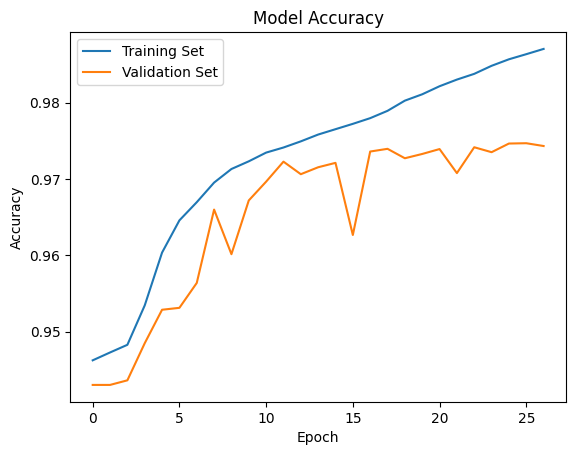

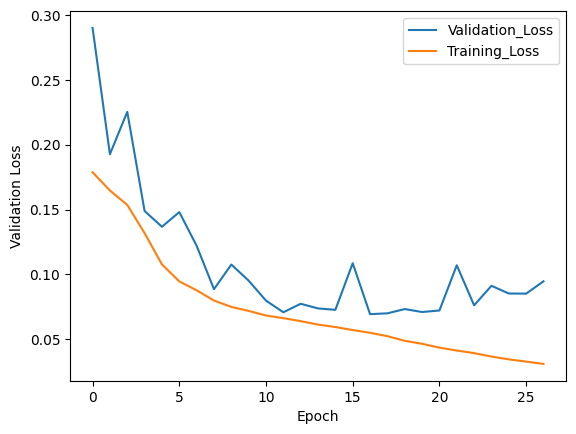

In [ ]:
print(results.history)
ax1 = plt.plot(results.history['accuracy'])
ax1 = plt.plot(results.history['val_accuracy'])
ax1 = plt.title('Model Accuracy')
ax1 = plt.ylabel('Accuracy')
ax1 = plt.xlabel('Epoch')
ax1 = plt.legend(['Training Set', 'Validation Set'])
plt.show()
ax2 = plt.plot(results.history['val_loss'])
ax2=plt.plot(results.history['loss'])
ax2 = plt.ylabel('Validation Loss')
ax2 = plt.xlabel('Epoch')
ax2 = plt.legend(['Validation_Loss', 'Training_Loss'])
plt.show()

8/8 ━━━━━━━━━━━━━━━━━━━━ 31s 2s/step
Precision     : 0.8213
Recall        : 0.6974
F1 Score      : 0.7543
Dice Score    : 0.7543
Accuracy      : 0.9767
IoU Score     : 0.6055
Confusion Matrix:
[[55750151   460472]
 [  918110  2115811]]


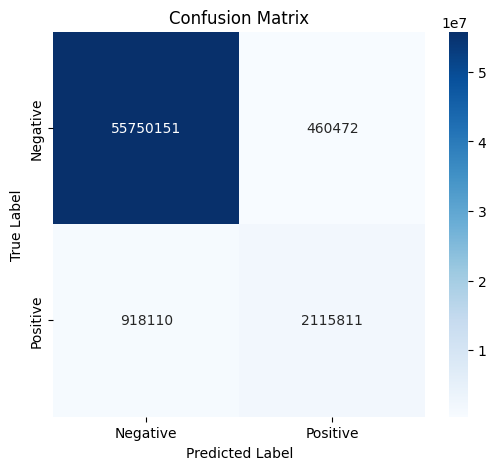

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix

# Assuming the rest of the code is already executed:
y_pred = model.predict(X_test)
y_pred_binary = (y_pred > 0.5).astype(np.bool_)
y_true_flat = y_test_ground_truth.flatten()
y_pred_flat = y_pred_binary.flatten()

# Metrics
precision = precision_score(y_true_flat, y_pred_flat)
recall = recall_score(y_true_flat, y_pred_flat)
f1 = f1_score(y_true_flat, y_pred_flat)
accuracy = accuracy_score(y_true_flat, y_pred_flat)
conf_matrix = confusion_matrix(y_true_flat, y_pred_flat)
tn, fp, fn, tp = confusion_matrix(y_true_flat, y_pred_flat).ravel()
iou = tp / (tp + fp + fn)
# Print metrics
print(f"Precision     : {precision:.4f}")
print(f"Recall        : {recall:.4f}")
print(f"F1 Score      : {f1:.4f}")
print(f"Dice Score    : {f1:.4f}")
print(f"Accuracy      : {accuracy:.4f}")
print(f"IoU Score     : {iou:.4f}")
print("Confusion Matrix:")
print(conf_matrix)

# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


In [ ]:
y_test_ground_truth = np.zeros((len(test_img_ids),img_width,img_height,1),dtype=np.bool_)

print('Resizing test masks')
for n,img_name in tqdm(enumerate(test_img_ids),total=len(test_img_ids)):
    mask = np.zeros((img_width,img_height,1),dtype=np.bool_)
    msk = imread(test_mask_dir+img_name)
    # If the mask is RGB, convert it to a 2D boolean mask first
    if msk.ndim == 3:
        msk = np.any(msk[:, :, :3] > 0, axis=-1)
    msk = np.expand_dims(resize(msk.astype(np.float32),(img_width,img_height),mode='constant',preserve_range=True),axis=-1)
    msk = msk > 0.5
    mask = np.maximum(mask,msk)
    y_test_ground_truth[n] = mask

In [ ]:
idx = random.randint(1,len(X_train))

pred_train = model.predict(X_train[:int(X_train.shape[0]*0.9)],verbose=1)
pred_val = model.predict(X_train[int(X_train.shape[0]*0.9):],verbose=1)
pred_test = model.predict(X_test,verbose=1)

pred_train = model.predict(X_train[:int(X_train.shape[0]*0.9)],verbose=1)
pred_val = model.predict(X_train[int(X_train.shape[0]*0.9):],verbose=1)
pred_test = model.predict(X_test,verbose=1)

#Probability thresholds --------------------------------------------------------------------
pred_train_t = (pred_train>0.3).astype(np.uint8)
pred_val_t = (pred_val>0.3).astype(np.uint8)
pred_test_t = (pred_test>0.3).astype(np.uint8)

#checking performance on entire test set

for i in range(0,test_img_count):

    imshow(X_test[i])
    plt.axis('off')
    plt.show()
    imshow(pred_test[i])
    #imshow(np.squeeze(pred_test[i]))
    plt.axis('off')
    plt.show()
    #imshow(np.squeeze(pred_test_t[i]))
    imshow(pred_test_t[i])
    plt.axis('off')
    plt.show()


In [ ]:
#checking performance on entire test set

for i in range(0,len(test_img_ids)):
    fig, ((ax0, ax1, ax2)) = plt.subplots(1,3, figsize=(20,7))

    ax0.imshow(X_test[i])
    ax0.axis('off')
    ax0.set_title('Satellite Map %s'%(test_img_ids[i]))

    ax1.imshow(np.squeeze(y_test_ground_truth[i]+0))
    ax1.axis('off')
    ax1.set_title('Ground Truth Mask %s'%(test_img_ids[i]))

    # continuous mask
    ax2.imshow(np.squeeze(pred_test_t[i]))
    ax2.axis('off')
    ax2.set_title('Predicted Mask %s'%(test_img_ids[i]))


Tuning on validation images...
  thr=0.30 gap= 0 spur= 0 -> val APLS 0.5336
  thr=0.30 gap= 0 spur=10 -> val APLS 0.5292
  thr=0.30 gap=20 spur= 0 -> val APLS 0.5299
  thr=0.30 gap=20 spur=10 -> val APLS 0.5217
  thr=0.40 gap= 0 spur= 0 -> val APLS 0.4677
  thr=0.40 gap= 0 spur=10 -> val APLS 0.4674
  thr=0.40 gap=20 spur= 0 -> val APLS 0.4793
  thr=0.40 gap=20 spur=10 -> val APLS 0.4791
  thr=0.50 gap= 0 spur= 0 -> val APLS 0.4113
  thr=0.50 gap= 0 spur=10 -> val APLS 0.4125
  thr=0.50 gap=20 spur= 0 -> val APLS 0.4374
  thr=0.50 gap=20 spur=10 -> val APLS 0.4386
Best settings: {'thr': 0.3, 'max_gap': 0, 'spur': 0}  (val APLS 0.5336)

Image 001 - APLS: 0.8628
Image 002 - APLS: 0.5140
Image 003 - APLS: 0.8190
Image 004 - APLS: 0.0000
Image 005 - APLS: 0.3209
Image 006 - APLS: 0.6648
Image 007 - APLS: 0.1884
Image 008 - APLS: 0.0000
Image 009 - APLS: 0.7449
Image 010 - APLS: 0.5668
Image 011 - APLS: 0.6346
Image 012 - APLS: 0.3131
Image 013 - APLS: 0.7347
Image 014 - APLS: 0.5980
Image 

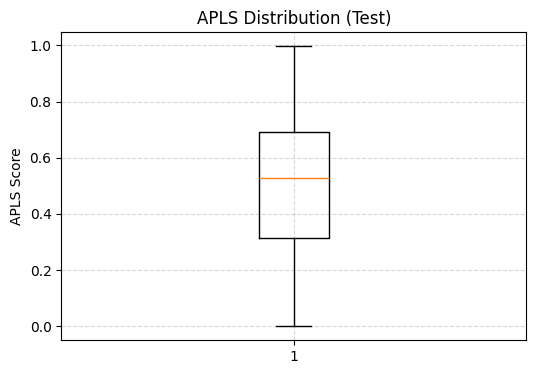

In [ ]:
# ============ APLS EVALUATION: improved, single cell ============
# Needs: model, X_test, y_test_ground_truth, X_train, y_train

import numpy as np, networkx as nx, random, itertools, matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy.ndimage import convolve
from skimage.morphology import skeletonize, remove_small_objects, binary_closing, disk
from skimage.measure import label
from skimage.draw import line

# ---------------- Settings ----------------
USE_TTA   = True            # 8x flip/rotate averaging (slower, better)
TUNE      = True            # tune postprocessing on VALIDATION data (not test)
N_VAL     = 20              # validation images used for tuning
GRID_THR  = (0.3, 0.4, 0.5)
GRID_GAP  = (0, 20)         # max gap (px) to bridge
GRID_SPUR = (0, 10)         # spur length (px) to prune
DEFAULT   = dict(thr=0.4, max_gap=20, spur=10)   # used if TUNE=False
MIN_SIZE, CLOSE_R = 150, 2
BUFFER, N_NODES, SEED = 4, 60, 42

# ---------------- Prediction (optional TTA) ----------------
def predict_probs(X, bs=4):
    if not USE_TTA:
        return model.predict(X, batch_size=bs, verbose=0)
    out = np.zeros(X.shape[:3] + (1,), np.float32)
    for k in range(4):
        for flip in (False, True):
            x = np.rot90(X, k, axes=(1, 2))
            if flip: x = x[:, :, ::-1]
            p = model.predict(np.ascontiguousarray(x), batch_size=bs, verbose=0)
            if flip: p = p[:, :, ::-1]
            out += np.rot90(p, -k, axes=(1, 2))
    return out / 8.0

# ---------------- Mask -> skeleton -> graph ----------------
def bridge_gaps(skel, max_gap):
    if max_gap <= 0: return skel
    skel = skel.copy()
    pts = np.argwhere(skel)
    if len(pts) < 2: return skel
    lab = label(skel, connectivity=2)
    nb = convolve(skel.astype(np.uint8), np.ones((3, 3), np.uint8), mode="constant") - 1
    ends = np.argwhere(skel & (nb == 1))
    tree = cKDTree(pts)
    kq = min(100, len(pts))
    for y, x in ends:
        d, j = tree.query([y, x], k=kq, distance_upper_bound=max_gap)
        for dd, jj in zip(np.atleast_1d(d), np.atleast_1d(j)):
            if np.isinf(dd): break
            py, px = pts[jj]
            if lab[py, px] != lab[y, x]:           # different component -> connect
                rr, cc = line(y, x, py, px); skel[rr, cc] = True
                break
    return skeletonize(skel)

def pred_to_skeleton(prob, thr, max_gap):
    m = prob.squeeze() > thr
    if CLOSE_R > 0: m = binary_closing(m, disk(CLOSE_R))
    if MIN_SIZE > 0: m = remove_small_objects(m, MIN_SIZE)
    return bridge_gaps(skeletonize(m), max_gap)

def skel_to_graph(skel):
    pts = set(map(tuple, np.argwhere(skel)[:, ::-1]))      # (x, y)
    G = nx.Graph(); G.add_nodes_from(pts)
    for (x, y) in pts:
        for dx, dy in ((1, 0), (0, 1), (1, 1), (1, -1)):   # each pair once
            q = (x + dx, y + dy)
            if q in pts: G.add_edge((x, y), q, weight=float(np.hypot(dx, dy)))
    return G

def prune_spurs(G, min_len):
    if min_len <= 0: return G
    G = G.copy()
    for n in [n for n in G.nodes if G.degree(n) == 1]:
        if n not in G: continue
        path, cur, prev = [n], n, None
        while True:
            nxt = [m for m in G.neighbors(cur) if m != prev]
            if len(nxt) != 1: break
            prev, cur = cur, nxt[0]; path.append(cur)
            if G.degree(cur) != 2: break
        if G.degree(cur) >= 3 and len(path) < min_len:
            G.remove_nodes_from(path[:-1])                  # keep the junction
    return G

def key_nodes(G): return [n for n in G.nodes if G.degree(n) != 2]

# ---------------- APLS (symmetric, snapped, normalised by GT length) ----------------
def apls_one_direction(G_a, G_b):
    nodes = key_nodes(G_a)
    if len(nodes) < 2: return None
    if G_b.number_of_nodes() == 0: return 0.0
    nodes = random.Random(SEED).sample(nodes, min(N_NODES, len(nodes)))
    b_nodes = list(G_b.nodes)
    dist, idx = cKDTree(np.array(b_nodes)).query(np.array(nodes))
    snap = [b_nodes[i] if d <= BUFFER else None for d, i in zip(dist, idx)]
    scores = []
    for i in range(len(nodes)):
        len_a = nx.single_source_dijkstra_path_length(G_a, nodes[i], weight="weight")
        len_b = (nx.single_source_dijkstra_path_length(G_b, snap[i], weight="weight")
                 if snap[i] is not None else {})
        for j in range(i + 1, len(nodes)):
            if nodes[j] not in len_a: continue              # no route in reference
            L_a = len_a[nodes[j]]
            if L_a == 0: continue
            if snap[i] is None or snap[j] is None or snap[j] not in len_b:
                scores.append(0.0)
            else:
                scores.append(1.0 - min(1.0, abs(L_a - len_b[snap[j]]) / L_a))
    return float(np.mean(scores)) if scores else None

def apls(G_gt, G_pr):
    p = apls_one_direction(G_gt, G_pr)                      # missed roads
    if p is None: return np.nan
    q = apls_one_direction(G_pr, G_gt); q = 0.0 if q is None else q   # false roads
    return 2 * p * q / (p + q + 1e-8)

def evaluate(probs, gts, thr, max_gap, spur, verbose=False):
    scores = []
    for i in range(len(probs)):
        G_gt = skel_to_graph(skeletonize(gts[i].squeeze() > 0.5))
        G_pr = prune_spurs(skel_to_graph(pred_to_skeleton(probs[i], thr, max_gap)), spur)
        s = apls(G_gt, G_pr); scores.append(s)
        if verbose:
            print(f"Image {i+1:03d} - APLS: {s:.4f}" if not np.isnan(s)
                  else f"Image {i+1:03d} - skipped (no GT roads)")
    return np.array(scores)

# ---------------- Tune on validation (never on test) ----------------
best = DEFAULT
if TUNE:
    if "va_idx" in globals():
        val_ids = va_idx
    else:                                                    # matches Keras validation_split=0.2
        val_ids = np.arange(int(len(X_train) * 0.8), len(X_train))
    val_ids = val_ids[:N_VAL]
    Pv, Gv = predict_probs(X_train[val_ids]), y_train[val_ids]
    best_score = -1
    print("Tuning on validation images...")
    for thr, gap, sp in itertools.product(GRID_THR, GRID_GAP, GRID_SPUR):
        sc = np.nanmean(evaluate(Pv, Gv, thr, gap, sp))
        print(f"  thr={thr:.2f} gap={gap:2d} spur={sp:2d} -> val APLS {sc:.4f}")
        if sc > best_score: best_score, best = sc, dict(thr=thr, max_gap=gap, spur=sp)
    print(f"Best settings: {best}  (val APLS {best_score:.4f})\n")

# ---------------- Final test evaluation ----------------
Y_pred_prob = predict_probs(X_test)
scores = evaluate(Y_pred_prob, y_test_ground_truth, verbose=True, **best)
valid = scores[~np.isnan(scores)]

print("\n=========== APLS SUMMARY (TEST) ===========")
print(f"Settings         : {best}")
print(f"Images evaluated : {len(valid)} / {len(scores)}")
print(f"Mean APLS        : {valid.mean():.4f}")
print(f"Median APLS      : {np.median(valid):.4f}")
print(f"Std              : {valid.std():.4f}")
print("===========================================")

plt.figure(figsize=(6, 4)); plt.boxplot(valid)
plt.ylabel("APLS Score"); plt.title("APLS Distribution (Test)")
plt.grid(True, linestyle="--", alpha=0.5); plt.show()

In [ ]:

import tensorflow as tf
import numpy as np
import time
import os
import statistics

# ==========================================
# 1. MODEL PARAMETER COUNT
# ==========================================

total_params = model.count_params()

trainable_params = np.sum([
    tf.keras.backend.count_params(w)
    for w in model.trainable_weights
])

non_trainable_params = total_params - trainable_params

print("\n========== MODEL PARAMETERS ==========")
print(f"Total Parameters       : {total_params:,}")
print(f"Trainable Parameters   : {trainable_params:,}")
print(f"Non-trainable Params   : {non_trainable_params:,}")
print(f"Total Parameters (M)   : {total_params / 1e6:.4f}")


# ==========================================
# 2. FLOPs CALCULATION
# ==========================================

def calculate_flops(model, input_shape=(1, 512, 512, 3)):

    try:
        from tensorflow.python.framework.convert_to_constants import (
            convert_variables_to_constants_v2
        )

        # Create a concrete inference function
        input_spec = tf.TensorSpec(
            shape=input_shape,
            dtype=tf.float32
        )

        @tf.function
        def forward_pass(x):
            return model(x, training=False)

        concrete_func = forward_pass.get_concrete_function(input_spec)

        # Freeze model variables
        frozen_func = convert_variables_to_constants_v2(
            concrete_func
        )

        graph_def = frozen_func.graph.as_graph_def()

        # Import frozen graph
        with tf.Graph().as_default() as graph:

            tf.graph_util.import_graph_def(
                graph_def,
                name=""
            )

            # Calculate floating-point operations
            profiler_options = (
                tf.compat.v1.profiler.ProfileOptionBuilder
                .float_operation()
            )

            profiler_options['output'] = 'none'

            flops_result = tf.compat.v1.profiler.profile(
                graph=graph,
                options=profiler_options
            )

        if flops_result is not None:
            return flops_result.total_float_ops

        return None

    except Exception as e:
        print("FLOPs calculation error:", str(e))
        return None


flops = calculate_flops(model)

print("\n========== COMPUTATIONAL COMPLEXITY ==========")

if flops is not None:
    print(f"Total FLOPs             : {flops:,}")
    print(f"FLOPs (G)               : {flops / 1e9:.4f}")
else:
    print("FLOPs could not be calculated.")


# ==========================================
# 3. INFERENCE SPEED (BATCH SIZE = 1)
# ==========================================

IMG_SIZE = 512
INPUT_CHANNELS = 3

# Single input image
dummy_input = np.random.rand(
    1, IMG_SIZE, IMG_SIZE, INPUT_CHANNELS
).astype(np.float32)

# Warm-up runs
for _ in range(20):
    output = model(dummy_input, training=False)
    _ = output.numpy()  # Synchronize execution

# Actual inference measurement
num_runs = 100
inference_times = []

for _ in range(num_runs):

    start_time = time.perf_counter()

    output = model(dummy_input, training=False)

    # Synchronize GPU/CPU execution
    _ = output.numpy()

    end_time = time.perf_counter()

    inference_times.append(
        (end_time - start_time) * 1000
    )

mean_latency = np.mean(inference_times)
median_latency = np.median(inference_times)
std_latency = np.std(inference_times)

throughput = 1000.0 / mean_latency

print("\n========== INFERENCE PERFORMANCE ==========")
print(f"Batch Size              : 1")
print(f"Number of Runs          : {num_runs}")
print(f"Mean Inference Time     : {mean_latency:.4f} ms")
print(f"Median Inference Time   : {median_latency:.4f} ms")
print(f"Standard Deviation      : {std_latency:.4f} ms")
print(f"Inference Throughput    : {throughput:.2f} images/sec")


# ==========================================
# 4. BATCH INFERENCE PERFORMANCE
# ==========================================

batch_size = 16

batch_input = np.random.rand(
    batch_size, IMG_SIZE, IMG_SIZE, INPUT_CHANNELS
).astype(np.float32)

# Warm-up
for _ in range(10):
    output = model(batch_input, training=False)
    _ = output.numpy()

batch_runs = 30
batch_times = []

for _ in range(batch_runs):

    start_time = time.perf_counter()

    output = model(batch_input, training=False)

    _ = output.numpy()

    end_time = time.perf_counter()

    batch_times.append(end_time - start_time)

mean_batch_time = np.mean(batch_times)

batch_latency = (mean_batch_time / batch_size) * 1000

batch_throughput = batch_size / mean_batch_time

print("\n========== BATCH INFERENCE PERFORMANCE ==========")
print(f"Batch Size              : {batch_size}")
print(f"Mean Batch Time         : {mean_batch_time * 1000:.4f} ms")
print(f"Latency Per Image       : {batch_latency:.4f} ms")
print(f"Batch Throughput        : {batch_throughput:.2f} images/sec")


# ==========================================
# 5. MODEL STORAGE SIZE
# ==========================================

model_path = "SE_Residual_Attention_UNet.keras"

model.save(model_path)

model_size_mb = os.path.getsize(model_path) / (1024 ** 2)

print("\n========== MODEL STORAGE ==========")
print(f"Model Size              : {model_size_mb:.2f} MB")


# ==========================================
# 6. FINAL COMPUTATIONAL SUMMARY
# ==========================================

print("\n========== FINAL MODEL SUMMARY ==========")

print(f"Parameters (M)          : {total_params / 1e6:.4f}")

if flops is not None:
    print(f"FLOPs (G)               : {flops / 1e9:.4f}")
else:
    print("FLOPs (G)               : Not available")

print(f"Model Size (MB)         : {model_size_mb:.2f}")
print(f"Inference Time (ms)     : {mean_latency:.4f}")
print(f"Throughput (img/sec)    : {throughput:.2f}")
print(f"Batch-16 Throughput     : {batch_throughput:.2f}")


Existing data detected successfully.
X_train: (6000, 512, 512, 3)
y_train: (6000, 512, 512, 1)
X_test: (226, 512, 512, 3)
y_test_ground_truth: (226, 512, 512, 1)

EXPERIMENT: D1
DILATION RATES: (3, 6, 9)
Total parameters: 9196209
Epoch 1/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step - accuracy: 0.9366 - loss: 0.2093
Epoch 1: val_loss improved from None to 3505.59595, saving model to ASPP_Sensitivity_Results/D1_best.keras

Epoch 1: finished saving model to ASPP_Sensitivity_Results/D1_best.keras
300/300 ━━━━━━━━━━━━━━━━━━━━ 126s 266ms/step - accuracy: 0.9454 - loss: 0.1827 - val_accuracy: 0.9430 - val_loss: 3505.5959
Epoch 2/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step - accuracy: 0.9481 - loss: 0.1681
Epoch 2: val_loss improved from 3505.59595 to 0.21059, saving model to ASPP_Sensitivity_Results/D1_best.keras

Epoch 2: finished saving model to ASPP_Sensitivity_Results/D1_best.keras
300/300 ━━━━━━━━━━━━━━━━━━━━ 74s 246ms/step - accuracy: 0.9473 - loss: 0.1691 - val_accuracy: 0.9430 - 

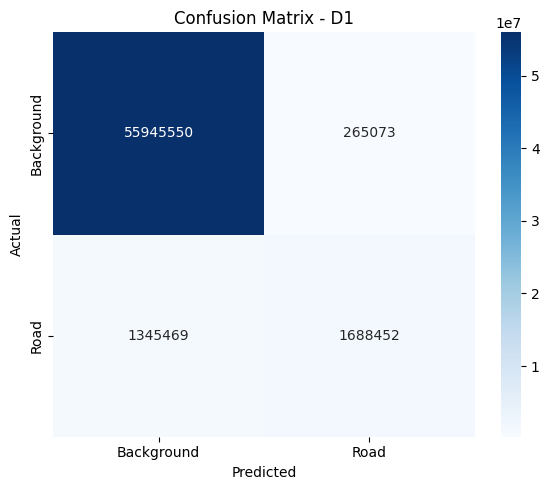


TESTING: D2
DILATION RATES: (4, 8, 12)
15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 455ms/step
Precision : 0.8356
Recall    : 0.5610
F1-score  : 0.6713
Dice      : 0.6713
Accuracy  : 0.9719
IoU       : 0.5053


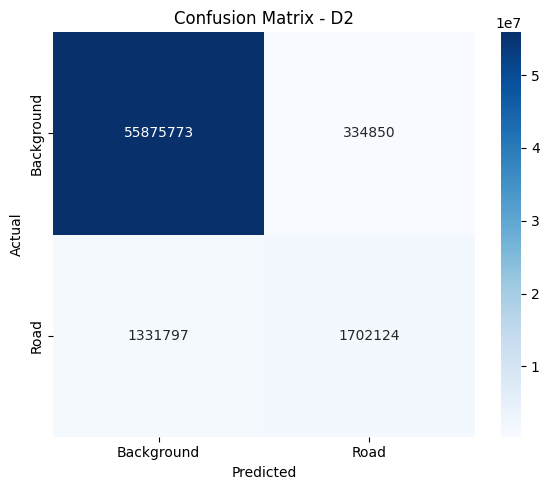


TESTING: D4
DILATION RATES: (8, 16, 24)
15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 443ms/step
Precision : 0.8151
Recall    : 0.5558
F1-score  : 0.6609
Dice      : 0.6609
Accuracy  : 0.9708
IoU       : 0.4935


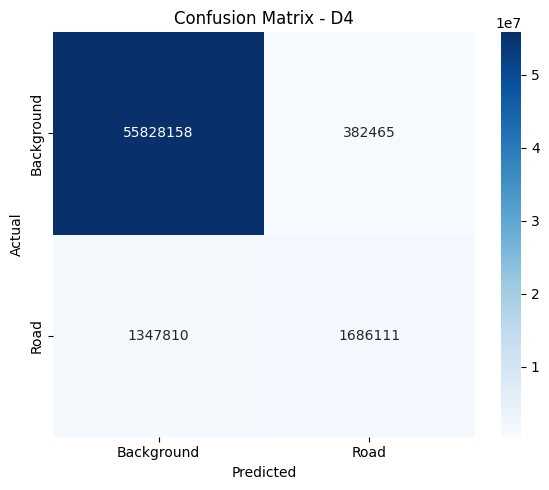


FINAL RESULTS
Experiment Dilation Rates  Precision   Recall  F1-Score     Dice  Accuracy      IoU
        D1      (3, 6, 9)   0.864310 0.556525  0.677081 0.677081  0.972815 0.511808
        D2     (4, 8, 12)   0.835614 0.561031  0.671331 0.671331  0.971868 0.505266
        D4    (8, 16, 24)   0.815107 0.555753  0.660896 0.660896  0.970794 0.493536


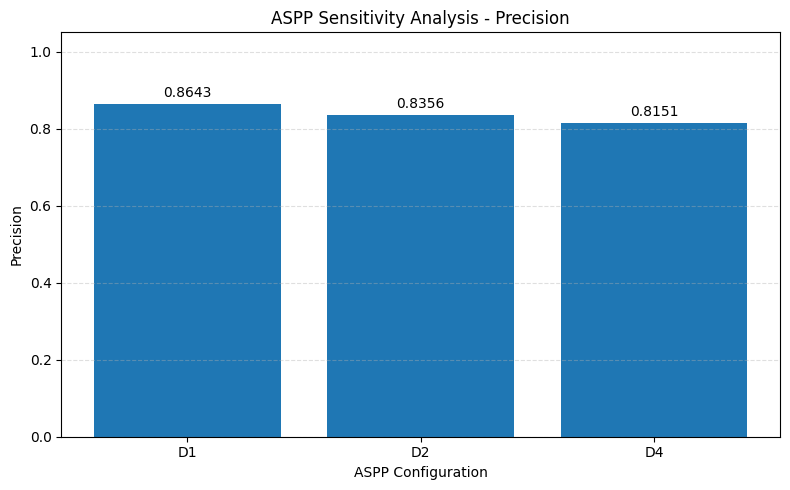

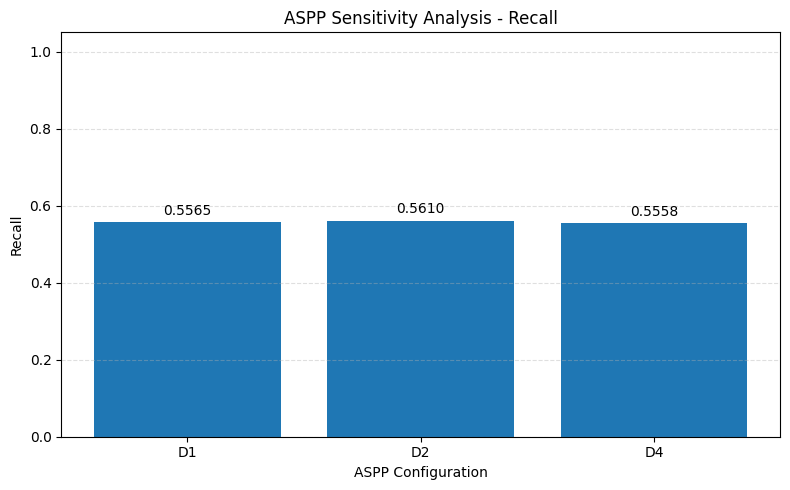

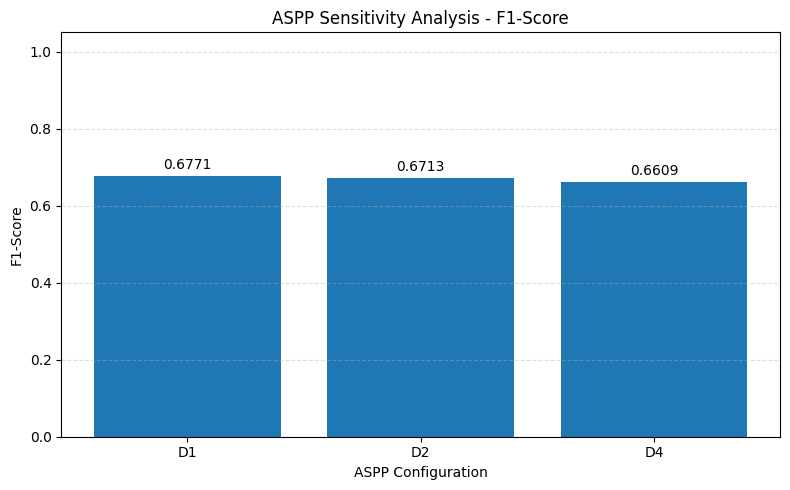

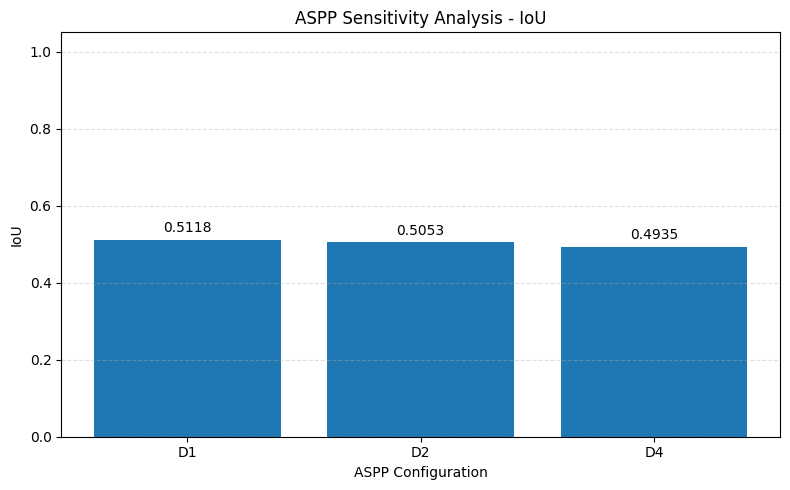

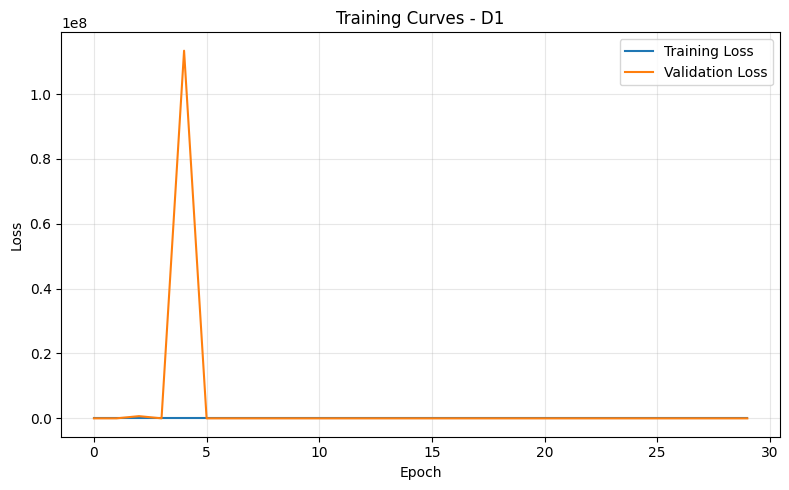

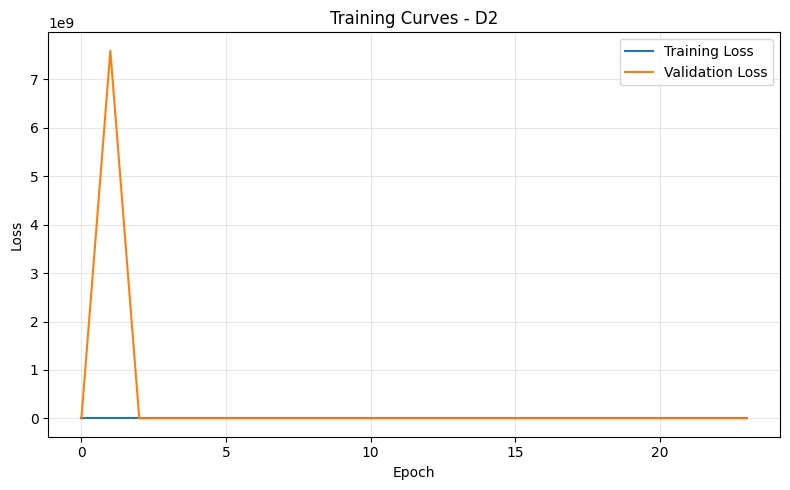

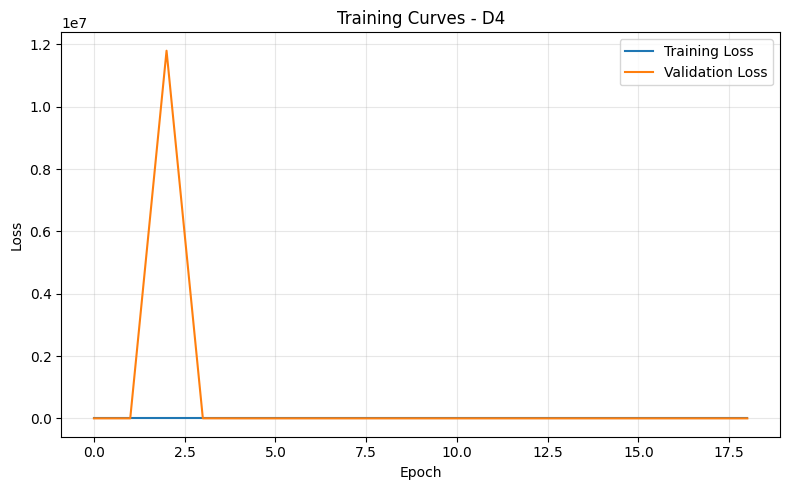


ASPP SENSITIVITY ANALYSIS COMPLETED
Results directory: ASPP_Sensitivity_Results


In [ ]:

# ================================================================
# ASPP DILATION RATE SENSITIVITY ANALYSIS
# Existing notebook model: attentionunet
#
# D1 = (3, 6, 9)
# D2 = (4, 8, 12)
# D4 = (8, 16, 24)
#
# Original configuration (6, 12, 18) is NOT retrained.
# ================================================================

import os
import gc
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras import layers, Model
from tensorflow.keras.layers import *
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix
)

# Fix np.random.seed if it was overwritten as an integer earlier in the notebook
if isinstance(np.random.seed, int):
    import importlib
    importlib.reload(np.random)

# ================================================================
# 1. CHECK EXISTING NOTEBOOK VARIABLES
# ================================================================

required_variables = [
    "X_train",
    "y_train",
    "X_test",
    "y_test_ground_truth",
    "input_shape"
]

for variable in required_variables:
    assert variable in globals(), f"{variable} is missing"

print("Existing data detected successfully.")

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test_ground_truth:", y_test_ground_truth.shape)

# ================================================================
# 2. CONFIGURABLE ASPP BLOCK
# ================================================================

def aspp_block(x, num_filters, rates=(6, 12, 18)):

    r1, r2, r3 = rates

    x1 = Conv2D(
        num_filters, (3, 3),
        dilation_rate=(r1, r1),
        padding="SAME"
    )(x)

    x1 = BatchNormalization()(x1)

    x2 = Conv2D(
        num_filters, (3, 3),
        dilation_rate=(r2, r2),
        padding="SAME"
    )(x)

    x2 = BatchNormalization()(x2)

    x3 = Conv2D(
        num_filters, (3, 3),
        dilation_rate=(r3, r3),
        padding="SAME"
    )(x)

    x3 = BatchNormalization()(x3)

    x4 = Conv2D(
        num_filters, (3, 3),
        dilation_rate=(1, 1),
        padding="SAME"
    )(x)

    x4 = BatchNormalization()(x4)

    y = Add()([x1, x2, x3, x4])

    y = Conv2D(
        num_filters, (1, 1),
        padding="SAME"
    )(y)

    return y


# ================================================================
# 3. CONFIGURABLE ATTENTIONUNET
# Uses your EXISTING encoder, decoder and attention functions.
# ================================================================

def attentionunet(input_shape, rates=(6, 12, 18)):

    n_filters = [16, 32, 64, 128, 256]

    inputs = layers.Input(input_shape)

    c0 = inputs

    c1 = stem_block(
        c0, n_filters[0], strides=1
    )

    # Encoder
    c2 = resnet_block(
        c1, n_filters[1], strides=2
    )

    c3 = resnet_block(
        c2, n_filters[2], strides=2
    )

    c4 = resnet_block(
        c3, n_filters[3], strides=2
    )

    c5 = resnet_block(
        c4, n_filters[4], strides=2
    )

    # ASPP bridge
    b1 = aspp_block(
        c5,
        n_filters[4],
        rates=rates
    )

    # Decoder
    d0 = attetion_block(c4, b1)
    d0 = UpSampling2D((2, 2))(d0)
    d0 = Concatenate()([d0, c4])
    d0 = resnet_block(d0, n_filters[4])

    d1 = attetion_block(c3, d0)
    d1 = UpSampling2D((2, 2))(d1)
    d1 = Concatenate()([d1, c3])
    d1 = resnet_block(d1, n_filters[3])

    d2 = attetion_block(c2, d1)
    d2 = UpSampling2D((2, 2))(d2)
    d2 = Concatenate()([d2, c2])
    d2 = resnet_block(d2, n_filters[2])

    d3 = attetion_block(c1, d2)
    d3 = UpSampling2D((2, 2))(d3)
    d3 = Concatenate()([d3, c1])
    d3 = resnet_block(d3, n_filters[1])

    # Output
    outputs = Conv2D(
        1, (1, 1),
        padding="same"
    )(d3)

    outputs = Activation(
        "sigmoid"
    )(outputs)

    return Model(inputs, outputs)


# ================================================================
# 4. EXPERIMENTAL CONFIGURATIONS
# ================================================================

dilation_configs = {
    "D1": (3, 6, 9),
    "D2": (4, 8, 12),
    "D4": (8, 16, 24)
}

# ================================================================
# 5. TRAINING PARAMETERS
# ================================================================

SEED = 42

EPOCHS = 100
BATCH_SIZE = 16
LEARNING_RATE = 0.001

OUTPUT_DIR = "ASPP_Sensitivity_Results"

os.makedirs(OUTPUT_DIR, exist_ok=True)

training_histories = {}

# ================================================================
# 6. TRAIN THREE EXPERIMENTS
# ================================================================

for exp_name, rates in dilation_configs.items():

    print("\n" + "=" * 65)
    print("EXPERIMENT:", exp_name)
    print("DILATION RATES:", rates)
    print("=" * 65)

    tf.keras.backend.clear_session()
    gc.collect()

    tf.keras.utils.set_random_seed(SEED)

    # Create model using existing architecture
    model = attentionunet(
        input_shape=input_shape,
        rates=rates
    )

    model.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    print("Total parameters:", model.count_params())

    checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath=f"{OUTPUT_DIR}/{exp_name}_best.keras",
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    )

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        min_delta=0.0001,
        mode="min",
        restore_best_weights=True,
        verbose=1
    )

    tensorboard = tf.keras.callbacks.TensorBoard(
        log_dir=f"{OUTPUT_DIR}/logs_{exp_name}"
    )

    history = model.fit(
        X_train,
        y_train,
        validation_split=0.2,
        batch_size=BATCH_SIZE,
        epochs=EPOCHS,
        callbacks=[
            checkpoint,
            early_stopping,
            tensorboard
        ],
        shuffle=True,
        verbose=1
    )

    training_histories[exp_name] = history.history

    np.save(
        f"{OUTPUT_DIR}/{exp_name}_history.npy",
        history.history
    )

    print(f"{exp_name} training completed.")

    del model
    tf.keras.backend.clear_session()
    gc.collect()


# ================================================================
# 7. TESTING AND METRIC CALCULATION
# ================================================================

evaluation_results = []

for exp_name, rates in dilation_configs.items():

    print("\n" + "=" * 65)
    print("TESTING:", exp_name)
    print("DILATION RATES:", rates)
    print("=" * 65)

    model = tf.keras.models.load_model(
        f"{OUTPUT_DIR}/{exp_name}_best.keras"
    )

    predictions = model.predict(
        X_test,
        batch_size=BATCH_SIZE,
        verbose=1
    )

    predictions_binary = (
        predictions > 0.5
    ).astype(np.uint8)

    y_true = np.asarray(
        y_test_ground_truth
    ).astype(np.uint8).flatten()

    y_pred = predictions_binary.flatten()

    assert len(y_true) == len(y_pred), \
        "Ground truth and prediction sizes differ."

    precision = precision_score(
        y_true, y_pred, zero_division=0
    )

    recall = recall_score(
        y_true, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_true, y_pred, zero_division=0
    )

    accuracy = accuracy_score(
        y_true, y_pred
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    iou = (
        tp / (tp + fp + fn)
        if tp + fp + fn > 0 else 0
    )

    dice = (
        2 * tp / (2 * tp + fp + fn)
        if 2 * tp + fp + fn > 0 else 0
    )

    evaluation_results.append({
        "Experiment": exp_name,
        "Dilation Rates": str(rates),
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "Dice": dice,
        "Accuracy": accuracy,
        "IoU": iou
    })

    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-score  : {f1:.4f}")
    print(f"Dice      : {dice:.4f}")
    print(f"Accuracy  : {accuracy:.4f}")
    print(f"IoU       : {iou:.4f}")

    # Confusion matrix
    cm = np.array([
        [tn, fp],
        [fn, tp]
    ])

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Background", "Road"],
        yticklabels=["Background", "Road"]
    )

    plt.title(f"Confusion Matrix - {exp_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{exp_name}_Confusion_Matrix.png",
        dpi=300
    )

    plt.show()
    plt.close()

    del model
    tf.keras.backend.clear_session()
    gc.collect()


# ================================================================
# 8. SAVE RESULTS
# ================================================================

results_df = pd.DataFrame(evaluation_results)

results_df.to_csv(
    f"{OUTPUT_DIR}/ASPP_Sensitivity_Results.csv",
    index=False
)

print("\nFINAL RESULTS")
print(results_df.to_string(index=False))


# ================================================================
# 9. COMPARATIVE METRIC PLOTS
# ================================================================

for metric in ["Precision", "Recall", "F1-Score", "IoU"]:

    plt.figure(figsize=(8, 5))

    bars = plt.bar(
        results_df["Experiment"],
        results_df[metric]
    )

    plt.bar_label(
        bars,
        fmt="%.4f",
        padding=3
    )

    plt.xlabel("ASPP Configuration")
    plt.ylabel(metric)
    plt.title(f"ASPP Sensitivity Analysis - {metric}")

    plt.ylim(0, 1.05)
    plt.grid(axis="y", linestyle="--", alpha=0.4)

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{metric}_Comparison.png",
        dpi=300
    )

    plt.show()
    plt.close()


# ================================================================
# 10. TRAINING LOSS CURVES
# ================================================================

for exp_name, history in training_histories.items():

    plt.figure(figsize=(8, 5))

    plt.plot(
        history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"Training Curves - {exp_name}")

    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{exp_name}_Loss_Curve.png",
        dpi=300
    )

    plt.show()
    plt.close()


print("\n" + "=" * 65)
print("ASPP SENSITIVITY ANALYSIS COMPLETED")
print("Results directory:", OUTPUT_DIR)
print("=" * 65)


Training images: (6000, 512, 512, 3)
Training masks: (6000, 512, 512, 1)
Test images: (226, 512, 512, 3)
Test masks: (226, 512, 512, 1)

STARTING: Ablation_1_No_ASPP
Total parameters: 6766001
Epoch 1/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step - accuracy: 0.9282 - loss: 0.2176
Epoch 1: val_loss improved from None to 0.21029, saving model to /content/AttentionUNet_Ablation_Results/Ablation_1_No_ASPP_best.keras

Epoch 1: finished saving model to /content/AttentionUNet_Ablation_Results/Ablation_1_No_ASPP_best.keras
300/300 ━━━━━━━━━━━━━━━━━━━━ 121s 259ms/step - accuracy: 0.9439 - loss: 0.1826 - val_accuracy: 0.9430 - val_loss: 0.2103 - learning_rate: 0.0010
Epoch 2/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/step - accuracy: 0.9486 - loss: 0.1550
Epoch 2: val_loss did not improve from 0.21029
300/300 ━━━━━━━━━━━━━━━━━━━━ 71s 237ms/step - accuracy: 0.9488 - loss: 0.1513 - val_accuracy: 0.9127 - val_loss: 11333.6416 - learning_rate: 0.0010
Epoch 3/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/

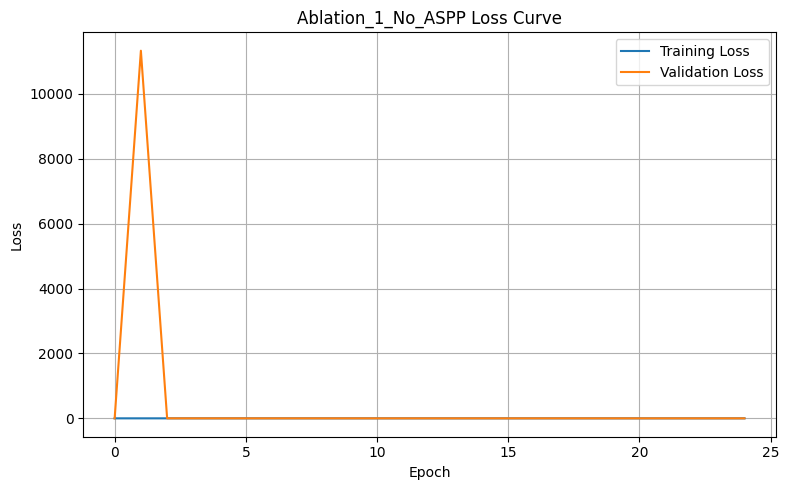


STARTING: Ablation_2_No_Attention
Total parameters: 5971121
Epoch 1/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step - accuracy: 0.9424 - loss: 0.1867
Epoch 1: val_loss improved from None to 0.17318, saving model to /content/AttentionUNet_Ablation_Results/Ablation_2_No_Attention_best.keras

Epoch 1: finished saving model to /content/AttentionUNet_Ablation_Results/Ablation_2_No_Attention_best.keras
300/300 ━━━━━━━━━━━━━━━━━━━━ 93s 187ms/step - accuracy: 0.9466 - loss: 0.1666 - val_accuracy: 0.9447 - val_loss: 0.1732 - learning_rate: 0.0010
Epoch 2/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step - accuracy: 0.9548 - loss: 0.1267
Epoch 2: val_loss improved from 0.17318 to 0.13627, saving model to /content/AttentionUNet_Ablation_Results/Ablation_2_No_Attention_best.keras

Epoch 2: finished saving model to /content/AttentionUNet_Ablation_Results/Ablation_2_No_Attention_best.keras
300/300 ━━━━━━━━━━━━━━━━━━━━ 50s 168ms/step - accuracy: 0.9574 - loss: 0.1171 - val_accuracy: 0.9507 - val_loss: 0

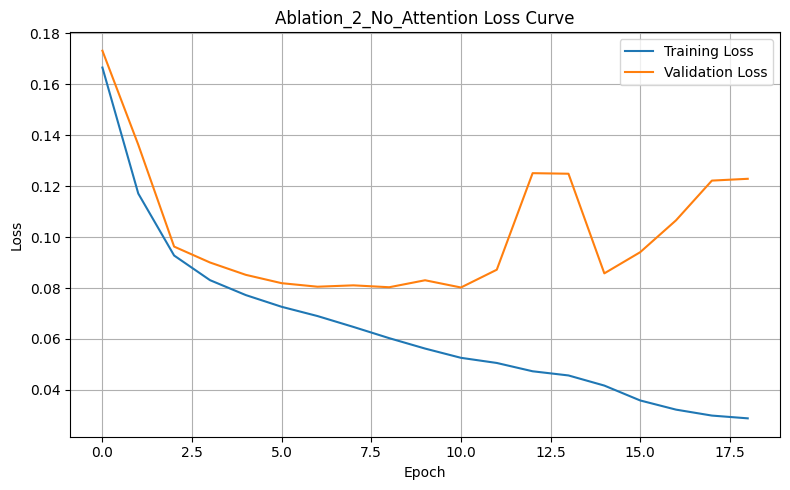


STARTING: Ablation_3_No_ASPP_No_Attention
Total parameters: 3540913
Epoch 1/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - accuracy: 0.9271 - loss: 0.2157
Epoch 1: val_loss improved from None to 0.16228, saving model to /content/AttentionUNet_Ablation_Results/Ablation_3_No_ASPP_No_Attention_best.keras

Epoch 1: finished saving model to /content/AttentionUNet_Ablation_Results/Ablation_3_No_ASPP_No_Attention_best.keras
300/300 ━━━━━━━━━━━━━━━━━━━━ 83s 176ms/step - accuracy: 0.9444 - loss: 0.1699 - val_accuracy: 0.9445 - val_loss: 0.1623 - learning_rate: 0.0010
Epoch 2/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - accuracy: 0.9571 - loss: 0.1178
Epoch 2: val_loss improved from 0.16228 to 0.12632, saving model to /content/AttentionUNet_Ablation_Results/Ablation_3_No_ASPP_No_Attention_best.keras

Epoch 2: finished saving model to /content/AttentionUNet_Ablation_Results/Ablation_3_No_ASPP_No_Attention_best.keras
300/300 ━━━━━━━━━━━━━━━━━━━━ 48s 160ms/step - accuracy: 0.9590 - loss: 0.1

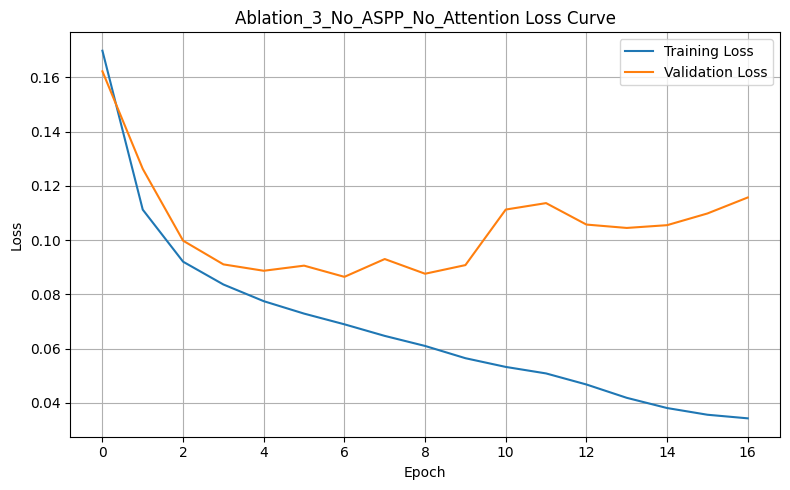


FINAL ABLATION STUDY RESULTS


,Model,Parameters,Best_Epoch,Accuracy,Precision,Recall,F1_Score,Dice,IoU,Training_Time_Min,Inference_Time_Per_Image_ms
0,Ablation_1_No_ASPP,6766001,15,97.4883,81.6783,65.6882,72.8158,72.8158,57.2522,30.6426,42.7463
1,Ablation_2_No_Attention,5971121,11,97.2810,78.1811,65.0636,71.0217,71.0217,55.0649,16.5907,38.9795
2,Ablation_3_No_ASPP_No_Attention,3540913,7,97.1823,81.3868,58.3129,67.9443,67.9443,51.4513,14.1651,33.9325



Results directory: /content/AttentionUNet_Ablation_Results
CSV file: Ablation_Study_Results.csv
All three ablation experiments completed successfully.


In [ ]:

# ================================================================
# COMPLETE ABLATION STUDY: ATTENTION U-NET
# Proposed model already trained; only three ablation variants
# SE retained in all variants
#
# A1: Without ASPP
# A2: Without Attention Gates
# A3: Without ASPP and Attention Gates
# ================================================================

import os
import gc
import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers, Model
from tensorflow.keras.layers import (
    Input, Conv2D, BatchNormalization, Activation,
    Add, Multiply, GlobalAveragePooling2D, Reshape,
    Dense, MaxPooling2D, UpSampling2D, Concatenate
)

from tensorflow.keras.callbacks import (
    EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
)

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

# ================================================================
# 1. EXPERIMENTAL CONFIGURATION
# ================================================================

SEED = 42
EPOCHS = 100
BATCH_SIZE = 16
THRESHOLD = 0.5

RESULT_DIR = "/content/AttentionUNet_Ablation_Results"
os.makedirs(RESULT_DIR, exist_ok=True)

# Existing notebook variables expected:
# X_train, y_train, X_test, y_test_ground_truth
#
# If your test masks are named y_test, replace the next line:
X_AB_TEST = X_test
Y_AB_TEST = y_test_ground_truth

INPUT_SHAPE = X_train.shape[1:]

assert X_AB_TEST.shape[0] == Y_AB_TEST.shape[0]
assert INPUT_SHAPE == (512, 512, 3)

print("Training images:", X_train.shape)
print("Training masks:", y_train.shape)
print("Test images:", X_AB_TEST.shape)
print("Test masks:", Y_AB_TEST.shape)

def stem_block_ab(inputs, n_filter, strides=1):

    x = Conv2D(
        n_filter, 3,
        strides=strides,
        padding="same",
        kernel_initializer="he_normal"
    )(inputs)

    x = BatchNormalization()(x)
    x = Activation("relu")(x)

    x = Conv2D(
        n_filter, 3,
        padding="same",
        kernel_initializer="he_normal"
    )(x)

    shortcut = Conv2D(
        n_filter, 1,
        strides=strides,
        padding="same",
        kernel_initializer="he_normal"
    )(inputs)

    shortcut = BatchNormalization()(shortcut)

    x = Add()([x, shortcut])

    # SE always enabled
    return x


# ================================================================
# 4. RESNET BLOCK
# ================================================================

def resnet_block_ab(inputs, n_filter, strides=1):

    x = BatchNormalization()(inputs)
    x = Activation("relu")(x)

    x = Conv2D(
        n_filter, 3,
        strides=strides,
        padding="same",
        kernel_initializer="he_normal"
    )(x)

    x = BatchNormalization()(x)
    x = Activation("relu")(x)

    x = Conv2D(
        n_filter, 3,
        padding="same",
        kernel_initializer="he_normal"
    )(x)

    shortcut = Conv2D(
        n_filter, 1,
        strides=strides,
        padding="same",
        kernel_initializer="he_normal"
    )(inputs)

    shortcut = BatchNormalization()(shortcut)

    return Add()([x, shortcut])


# ================================================================
# 5. ASPP BLOCK
# Original active rates: 6, 12, 18
# Standard convolution branch also included
# ================================================================

def aspp_block_ab(inputs, n_filters=256):

    branches = []

    for rate in [6, 12, 18]:

        x = Conv2D(
            n_filters,
            3,
            dilation_rate=(rate, rate),
            padding="same",
            kernel_initializer="he_normal"
        )(inputs)

        x = BatchNormalization()(x)

        branches.append(x)

    # Standard 3x3 convolution branch
    x = Conv2D(
        n_filters,
        3,
        padding="same",
        kernel_initializer="he_normal"
    )(inputs)

    x = BatchNormalization()(x)

    branches.append(x)

    x = Add()(branches)

    x = Conv2D(
        n_filters,
        1,
        padding="same",
        kernel_initializer="he_normal"
    )(x)

    return x


# ================================================================
# 6. ATTENTION GATE
# Original design without sigmoid normalization
# ================================================================

def attention_block_ab(g, x):

    filters = int(x.shape[-1])

    g1 = BatchNormalization()(g)
    g1 = Activation("relu")(g1)

    g1 = Conv2D(
        filters, 3,
        padding="same",
        kernel_initializer="he_normal"
    )(g1)

    g1 = MaxPooling2D(pool_size=(2, 2))(g1)

    x1 = BatchNormalization()(x)
    x1 = Activation("relu")(x1)

    x1 = Conv2D(
        filters, 3,
        padding="same",
        kernel_initializer="he_normal"
    )(x1)

    combined = Add()([g1, x1])

    combined = BatchNormalization()(combined)
    combined = Activation("relu")(combined)

    combined = Conv2D(
        filters, 3,
        padding="same",
        kernel_initializer="he_normal"
    )(combined)

    output = Multiply()([x1, combined])

    return output


# ================================================================
# 7. CONFIGURABLE ATTENTION U-NET
# ================================================================

def attentionunet_ab(
    input_shape=(512, 512, 3),
    use_aspp=True,
    use_attention=True
):

    n_filters = [16, 32, 64, 128, 256]

    inputs = Input(shape=input_shape)

    # Encoder
    c1 = stem_block_ab(inputs, n_filters[0], strides=1)

    c2 = resnet_block_ab(c1, n_filters[1], strides=2)

    c3 = resnet_block_ab(c2, n_filters[2], strides=2)

    c4 = resnet_block_ab(c3, n_filters[3], strides=2)

    c5 = resnet_block_ab(c4, n_filters[4], strides=2)

    # Bridge
    b1 = (
        aspp_block_ab(c5, n_filters=256)
        if use_aspp else c5
    )

    # Decoder 1
    d0 = (
        attention_block_ab(c4, b1)
        if use_attention else b1
    )

    d0 = UpSampling2D((2, 2))(d0)
    d0 = Concatenate()([d0, c4])
    d0 = resnet_block_ab(d0, n_filters[4], strides=1)

    # Decoder 2
    d1 = (
        attention_block_ab(c3, d0)
        if use_attention else d0
    )

    d1 = UpSampling2D((2, 2))(d1)
    d1 = Concatenate()([d1, c3])
    d1 = resnet_block_ab(d1, n_filters[3], strides=1)

    # Decoder 3
    d2 = (
        attention_block_ab(c2, d1)
        if use_attention else d1
    )

    d2 = UpSampling2D((2, 2))(d2)
    d2 = Concatenate()([d2, c2])
    d2 = resnet_block_ab(d2, n_filters[2], strides=1)

    # Decoder 4
    d3 = (
        attention_block_ab(c1, d2)
        if use_attention else d2
    )

    d3 = UpSampling2D((2, 2))(d3)
    d3 = Concatenate()([d3, c1])
    d3 = resnet_block_ab(d3, n_filters[1], strides=1)

    outputs = Conv2D(
        1, 1,
        activation="sigmoid",
        padding="same"
    )(d3)

    return Model(inputs, outputs)


# ================================================================
# 8. METRIC CALCULATION
# ================================================================

def calculate_metrics(y_true, y_pred):

    y_true = (
        np.asarray(y_true) > 0.5
    ).astype(np.uint8)

    y_pred = (
        np.asarray(y_pred) > THRESHOLD
    ).astype(np.uint8)

    yt = y_true.ravel()
    yp = y_pred.ravel()

    cm = confusion_matrix(
        yt, yp,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    accuracy = accuracy_score(yt, yp)

    precision = precision_score(
        yt, yp,
        zero_division=0
    )

    recall = recall_score(
        yt, yp,
        zero_division=0
    )

    f1 = f1_score(
        yt, yp,
        zero_division=0
    )

    iou = tp / (tp + fp + fn + 1e-7)

    dice = (2 * tp) / (
        2 * tp + fp + fn + 1e-7
    )

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1,
        "Dice": dice,
        "IoU": iou,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Confusion_Matrix": cm
    }


# ================================================================
# 9. ABLATION CONFIGURATIONS
# ================================================================

ABLATION_CONFIGS = {

    "Ablation_1_No_ASPP": {
        "use_aspp": False,
        "use_attention": True
    },

    "Ablation_2_No_Attention": {
        "use_aspp": True,
        "use_attention": False
    },

    "Ablation_3_No_ASPP_No_Attention": {
        "use_aspp": False,
        "use_attention": False
    }

}


# ================================================================
# 10. TRAIN AND EVALUATE THREE ABLATION MODELS
# ================================================================

ablation_results = []
ablation_histories = {}
ablation_confusion_matrices = {}

for model_name, config in ABLATION_CONFIGS.items():

    print("\n" + "=" * 70)
    print("STARTING:", model_name)
    print("=" * 70)

    tf.keras.utils.set_random_seed(SEED)

    # Build model
    ablation_model = attentionunet_ab(
        input_shape=INPUT_SHAPE,
        use_aspp=config["use_aspp"],
        use_attention=config["use_attention"]
    )

    # Compile
    ablation_model.compile(
        optimizer=tf.keras.optimizers.Adam(),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    total_params = ablation_model.count_params()

    print("Total parameters:", total_params)

    checkpoint_path = os.path.join(
        RESULT_DIR,
        model_name + "_best.keras"
    )

    callbacks = [

        ModelCheckpoint(
            checkpoint_path,
            monitor="val_loss",
            save_best_only=True,
            mode="min",
            verbose=1
        ),

        EarlyStopping(
            monitor="val_loss",
            patience=10,
            min_delta=0.0001,
            restore_best_weights=True,
            verbose=1
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=5,
            min_lr=1e-7,
            verbose=1
        )

    ]

    # Training
    training_start = time.time()

    history = ablation_model.fit(
        X_train,
        y_train,
        validation_split=0.2,
        batch_size=BATCH_SIZE,
        epochs=EPOCHS,
        callbacks=callbacks,
        shuffle=True,
        verbose=1
    )

    training_time = time.time() - training_start

    ablation_histories[model_name] = history.history

    best_epoch = (
        int(np.argmin(history.history["val_loss"])) + 1
    )

    # Load best saved model
    del ablation_model
    gc.collect()

    ablation_model = tf.keras.models.load_model(
        checkpoint_path,
        compile=False
    )

    # Prediction
    inference_start = time.time()

    predictions = ablation_model.predict(
        X_AB_TEST,
        batch_size=BATCH_SIZE,
        verbose=1
    )

    inference_time = time.time() - inference_start

    # Metrics
    metrics = calculate_metrics(
        Y_AB_TEST,
        predictions
    )

    ablation_confusion_matrices[model_name] = (
        metrics["Confusion_Matrix"]
    )

    result = {

        "Model": model_name,

        "Parameters": ablation_model.count_params(),

        "Best_Epoch": best_epoch,

        "Training_Time_Min": training_time / 60,

        "Inference_Time_Sec": inference_time,

        "Inference_Time_Per_Image_ms":
            (inference_time / len(X_AB_TEST)) * 1000,

        "Accuracy": metrics["Accuracy"],

        "Precision": metrics["Precision"],

        "Recall": metrics["Recall"],

        "F1_Score": metrics["F1_Score"],

        "Dice": metrics["Dice"],

        "IoU": metrics["IoU"],

        "TN": metrics["TN"],

        "FP": metrics["FP"],

        "FN": metrics["FN"],

        "TP": metrics["TP"]

    }

    ablation_results.append(result)

    print("\nRESULTS:", model_name)

    for key, value in result.items():
        print(f"{key}: {value}")

    # Save confusion matrix
    np.savetxt(
        os.path.join(
            RESULT_DIR,
            model_name + "_Confusion_Matrix.csv"
        ),
        metrics["Confusion_Matrix"],
        delimiter=",",
        fmt="%d"
    )

    # Save loss curve
    plt.figure(figsize=(8, 5))

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(model_name + " Loss Curve")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            RESULT_DIR,
            model_name + "_Loss.png"
        ),
        dpi=300
    )

    plt.show()
    plt.close()

    # Release memory
    del ablation_model
    del predictions
    gc.collect()


# ================================================================
# 11. FINAL RESULTS TABLE
# ================================================================

ablation_df = pd.DataFrame(ablation_results)

ablation_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "Ablation_Study_Results.csv"
    ),
    index=False
)

display_columns = [
    "Model",
    "Parameters",
    "Best_Epoch",
    "Accuracy",
    "Precision",
    "Recall",
    "F1_Score",
    "Dice",
    "IoU",
    "Training_Time_Min",
    "Inference_Time_Per_Image_ms"
]

ablation_display = ablation_df[display_columns].copy()

percentage_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1_Score",
    "Dice",
    "IoU"
]

ablation_display[percentage_columns] *= 100

print("\n" + "=" * 70)
print("FINAL ABLATION STUDY RESULTS")
print("=" * 70)

display(ablation_display.round(4))

print("\nResults directory:", RESULT_DIR)
print("CSV file: Ablation_Study_Results.csv")
print("All three ablation experiments completed successfully.")
